<a href="https://colab.research.google.com/github/ichaxpro/244107020023-Machine-Learning/blob/master/JS09/JS09_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1 - Install the ANNOY Library

In [ ]:
# Install ANNOY
!pip install annoy

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/647.5 kB ? eta -:--:--
     ---------------- ----------------------- 


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Python313\python.exe -m pip install --upgrade pip


Step 2 - Import Libraries

In [ ]:
# Import Library
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

Step 3 - Creating a Dummy Dataset

In [ ]:
# Build Random Dataset and Query Point
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # random values in a 100x100 space

# Query point (pick 1 random data point)
query = X[np.random.randint(0, n_points)]

Step 4 - Exact NN

In [ ]:
# Compute Exact NN Using Brute Force
# It will visit the data one by one
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # take the 3 nearest
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN distances:", distances[idx_exact])
print("Exact Time:", round(time_exact*1000, 4), "ms")

Exact NN index: [219 898 593]
Exact NN distances: [0.         1.36915938 2.27931544]
Exact Time: 5.6829 ms


Step 5 - Distance Computation with ANNOY

In [ ]:
# ANNOY 3 Trees
f = 2  # dimensions
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # find 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN distances:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Annoy Time:", round(time_ann*1000, 4), "ms")


Annoy NN index: [219, 898, 593]
Annoy NN distances: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Annoy Time: 0.4449 ms


Step 6 - Visualizing NN Results

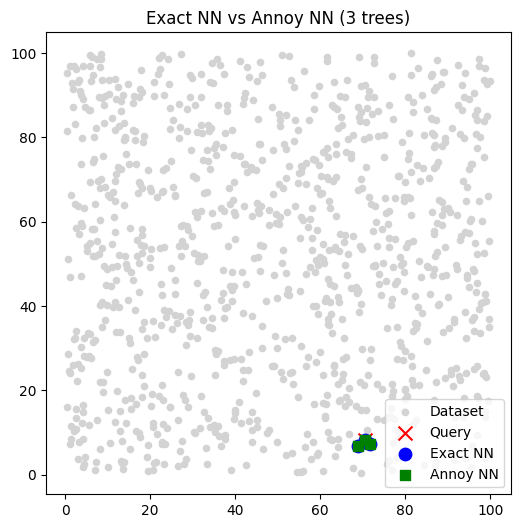

In [ ]:
# Visualize
# Knowing the NN produced by Exact NN and ANNOY
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN marked in blue
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN marked in green
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()